In [15]:
# augmentation version 1: here, ONLY angry and sad were augmented.
# happy was left alone, and its count was used as the target amount for angry and sad.
# all three classes are now equal at 4673 images each.

In [16]:
from pathlib import Path
from collections import Counter

from capstone_data.image_loader import load_dataset

data_path = Path.home() / "Downloads" / "cleaned_data"

print("Dataset path:", data_path)
print("Dataset folder exists:", data_path.exists())


Dataset path: /Users/melissatobias/Downloads/cleaned_data
Dataset folder exists: True


In [17]:
from capstone_data.image_loader import load_dataset 
from collections import Counter

data_path = Path.home() / "Downloads" / "cleaned_data"

dataset = load_dataset (data_path)

print (f"Total images: {len (dataset)}")

print("\nImages per class:")
class_counts = Counter (item["class_name"] for item in dataset)

for class_name, count in class_counts. items():
    print (f"{class_name}: {count}")

if class_counts:
    print(f"\nTotal classes found: {len(class_counts)}")
    print(f"Largest class: {max(class_counts, key=class_counts.get)}")
    print(f"Smallest class: {min(class_counts, key=class_counts.get)}")

Total images: 16779

Images per class:
angry: 3089
happy: 6677
sad: 1207
neutral: 5806

Total classes found: 4
Largest class: happy
Smallest class: sad


In [18]:
# splitting 70-15-15

import pandas as pd
from sklearn.model_selection import train_test_split
from collections import Counter

# convert the loader's records into a DataFrame
df = pd.DataFrame(dataset)

# use each record's class name as its stratification label
X = df
y = df["class_name"].str.lower()

# reserve 15% for the final test set
train_val_df, test_df = train_test_split(
    df,
    test_size=0.15,
    random_state=42,
    stratify=y)

# reserve 15% of the original data for validation.
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=train_val_df["class_name"].str.lower())

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))


Training images: 11745
Validation images: 2517
Test images: 2517
Total: 16779


In [19]:
# checking distributions after split

classes = ["angry", "happy", "sad"]

for split_name, split_df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)]:
    print(f"\n{split_name} distribution:")

    counts = Counter(split_df["class_name"].str.lower())

    for class_name in classes:
        print(f"  {class_name.capitalize():<8}: {counts.get(class_name, 0)}")



Training distribution:
  Angry   : 2163
  Happy   : 4673
  Sad     : 845

Validation distribution:
  Angry   : 463
  Happy   : 1002
  Sad     : 181

Test distribution:
  Angry   : 463
  Happy   : 1002
  Sad     : 181


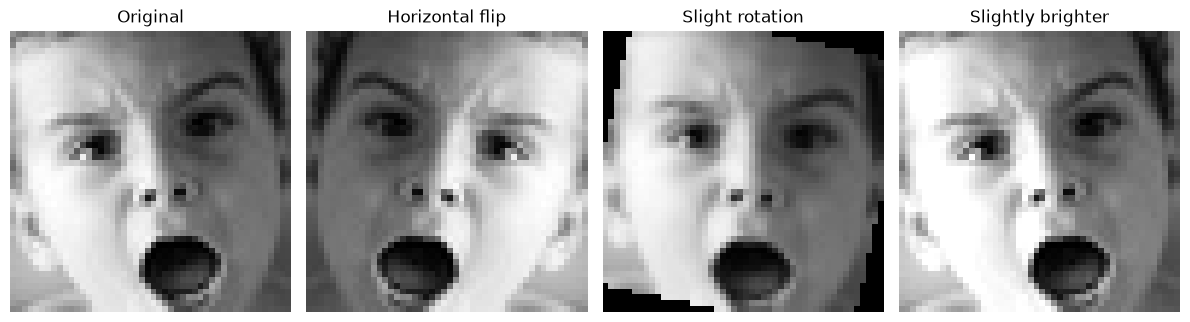

In [20]:

from PIL import Image, ImageEnhance
import matplotlib.pyplot as plt
import random

random.seed(42)

# using one angry training image
angry_rows = train_df[
    train_df["class_name"].str.lower() == "angry"]

test = random.choice(angry_rows["path"].tolist())

original = Image.open(test).convert("L")
original_size = original.size

flipped = original.transpose(Image.Transpose.FLIP_LEFT_RIGHT)

rotated = original.rotate(
    random.uniform(-13, 13),
    resample=Image.Resampling.BILINEAR)

image = rotated.resize(
    original_size,
    resample=Image.Resampling.LANCZOS)

brighter = ImageEnhance.Brightness(original).enhance(1.1)

fig, axes = plt.subplots(1, 4, figsize=(12, 4))

images = [original, flipped, rotated, brighter]
titles = ["Original", "Horizontal flip", "Slight rotation", "Slightly brighter"]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [21]:

from pathlib import Path
from collections import Counter
from PIL import Image, ImageEnhance, ImageOps
import random
import pandas as pd

random.seed(42)

output = Path.home() / "Downloads" / "Capstone-DATA4381" / "augmentation" / "aug_data_v1"

# 4,673 training images per class to match happy
target = 4673

classes = ["angry", "happy", "sad"]

if output.exists():
    raise FileExistsError(
        f"{output} already exists.")

output.mkdir(parents=True)

# count original training images by class
train_counts = Counter(
    train_df["class_name"].str.lower())

print("Output folder:", output)
print("\nOriginal training counts:")

for class_name in classes:
    print(f"{class_name.capitalize():<10}: {train_counts[class_name]}")


Output folder: /Users/melissatobias/Downloads/Capstone-DATA4381/augmentation/aug_data_v1

Original training counts:
Angry     : 2163
Happy     : 4673
Sad       : 845


In [22]:

def augment_grayscale(image):
    image = image.convert("L")
    original_size = image.size

    # random horizontal flip
    if random.random() < 0.5:
        image = ImageOps.mirror(image)

    # small rotation
    if random.random() < 0.7:
        angle = random.uniform(-13, 13)

        rotated = image.rotate(
            angle,
            resample=Image.Resampling.BICUBIC,
            expand=True,
            fillcolor=0)

        # restore original dimensions without cropping the image
        image = rotated.resize(
            original_size,
            resample=Image.Resampling.LANCZOS)

    # brightness adjustment
    if random.random() < 0.5:
        factor = random.uniform(0.9, 1.1)
        image = ImageEnhance.Brightness(image).enhance(factor)

    # contrast adjustment
    if random.random() < 0.5:
        factor = random.uniform(0.9, 1.1)
        image = ImageEnhance.Contrast(image).enhance(factor)

    return image.convert("L")

In [23]:

# generate the augmented training dataset

for class_name in classes:
    class_df = train_df[
        train_df["class_name"].str.lower() == class_name
    ].reset_index(drop=True)

    class_output = output/class_name
    class_output.mkdir(parents=True, exist_ok=True)

    original_count = len(class_df)
    target_count = max(target, original_count)
    
    print(f"\nOriginal {class_name} images: {original_count}")

    # load and save original training images as grayscale
    original_images = []

    for index, row in class_df.iterrows():
        with Image.open(row["path"]) as img:
            gray_img = img.convert("L").copy()

        original_images.append(gray_img)

        gray_img.save(
            class_output / f"original_{index:06d}.jpg",
            format="JPEG",
            quality=95)

    # generate extra images only when the class needs them
    additional_needed = target_count - original_count

    for index in range(additional_needed):
        # augmenting already-augmented copies if needed
        source_img = random.choice(original_images)
        augmented_img = augment_grayscale(source_img)

        augmented_img.save(
            class_output / f"augmented_{index:06d}.jpg",
            format="JPEG",
            quality=95)

    print(f"New generated images: {additional_needed}")
    print(f"New total: {original_count + additional_needed}")

print("\nExport location:", output)


Original angry images: 2163
New generated images: 2510
New total: 4673

Original happy images: 4673
New generated images: 0
New total: 4673

Original sad images: 845
New generated images: 3828
New total: 4673

Export location: /Users/melissatobias/Downloads/Capstone-DATA4381/augmentation/aug_data_v1
